# Chord transcription demo

Runs the RWC evaluation, plots the results, and transcribes one song so you can listen along with the predicted chords.

The model is a CNN on constant-Q spectrogram windows that predicts root, quality, seventh and extensions with separate heads, followed by a second-order HSMM that decodes a chord sequence with realistic transitions and durations.

## Setup

Run from the repository root or from `notebooks/`, with the packages from `requirements.txt` installed.

In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

ROOT = Path.cwd().resolve()
if not (ROOT / 'chordrec').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'models/best_model.pt').is_file(), 'Could not find the repository root.'
env = {**os.environ, 'PYTHONPATH': str(ROOT)}

## How it works

A chord isn't really one class. The root says where the harmony is centred, the quality gives its basic colour, the seventh changes its tension and function, and extensions add more colour on top. The CNN predicts these with separate heads, where later heads see the earlier predictions, so it's easier to tell a dominant seventh once you know the root and quality. It also makes the errors easier to read.

The CQT keeps pitch relationships linear, so a chord shifted up a semitone just shifts its pattern. The CNN turns short time-frequency windows into probabilities, and the second-order HSMM smooths them over time while modelling chord transitions and durations. That removes most of the one-frame flicker and picks up common progressions like tonic, predominant, dominant.

## RWC evaluation

Scores on the fixed 15-song test split. **Frame accuracy** weights every analysis frame equally; **duration-weighted** accuracy weights each frame by its time span.

The first set is CNN-only on annotation-aligned windows. The second compares CNN-only against CNN + HSMM on the same continuous 0.2 s frames, using posteriors saved from the full audio pipeline so this runs without recomputing the CQT for every song. Results are given at root, root + quality, and root + quality + seventh level.

In [2]:
subprocess.run([sys.executable, 'scripts/evaluate.py'], cwd=ROOT, env=env, check=True,
               stdout=subprocess.DEVNULL)
report = json.loads((ROOT / 'results/rwc_evaluation.json').read_text())
print(f"CNN-only: {len(report['per_song'])} songs")
print(f"CNN vs CNN + HSMM: {len(report['continuous_pipeline_comparison'])} songs")

CNN-only: 15 songs
CNN vs CNN + HSMM: 15 songs


### Aggregate metrics

Macro averages, so every song counts equally.

Evaluation,Chord components,Score
Frame accuracy,Root,88.32%
Frame accuracy,Root + quality,82.68%
Frame accuracy,Root + quality + seventh,70.09%
Duration-weighted accuracy,Root,89.90%
Duration-weighted accuracy,Root + quality,84.39%
Duration-weighted accuracy,Root + quality + seventh,71.14%


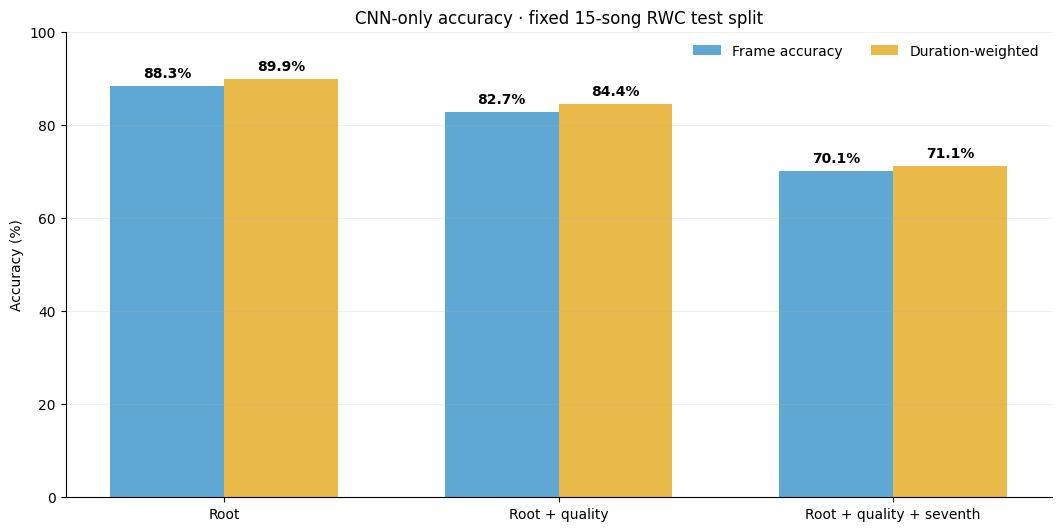

System,Evaluation,Chord components,Score
CNN only,Frame accuracy,Root,80.70%
CNN only,Frame accuracy,Root + quality,74.76%
CNN only,Frame accuracy,Root + quality + seventh,60.18%
CNN only,Duration-weighted accuracy,Root,80.70%
CNN only,Duration-weighted accuracy,Root + quality,74.76%
CNN only,Duration-weighted accuracy,Root + quality + seventh,60.18%
CNN + HSMM,Frame accuracy,Root,83.27%
CNN + HSMM,Frame accuracy,Root + quality,78.97%
CNN + HSMM,Frame accuracy,Root + quality + seventh,65.90%
CNN + HSMM,Duration-weighted accuracy,Root,83.27%


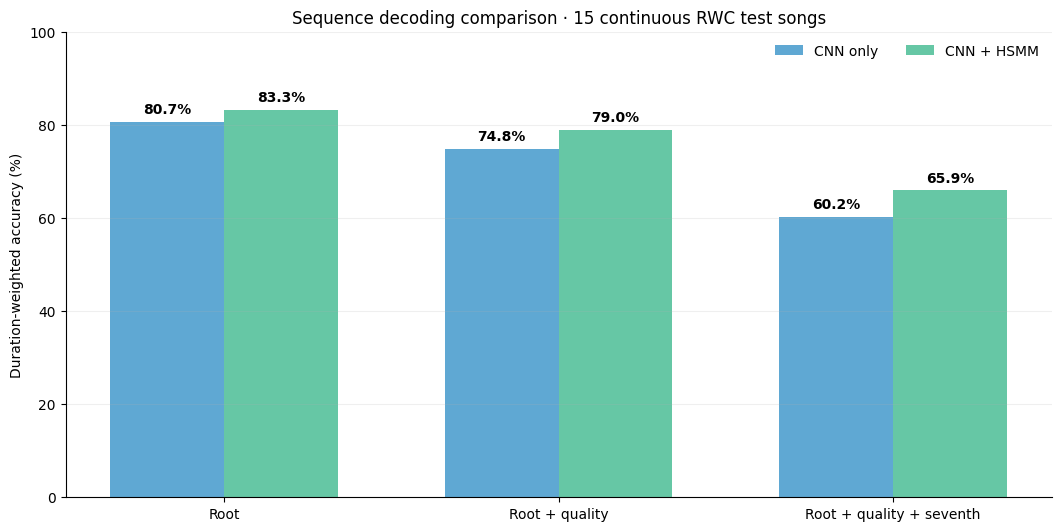

In [3]:
metric_info = [
    ('root_accuracy', 'Root', 'Frame accuracy'),
    ('root_quality_accuracy', 'Root + quality', 'Frame accuracy'),
    ('root_quality_seventh_accuracy', 'Root + quality + seventh', 'Frame accuracy'),
    ('song_root_percent', 'Root', 'Duration-weighted accuracy'),
    ('song_root_quality_percent', 'Root + quality', 'Duration-weighted accuracy'),
    ('song_root_quality_seventh_percent', 'Root + quality + seventh', 'Duration-weighted accuracy'),
]
metrics = report['cnn_only_macro_average']
aggregate = pd.DataFrame([
    {'Evaluation': evaluation, 'Chord components': components, 'Score': metrics[key]}
    for key, components, evaluation in metric_info
])
display(aggregate.style.hide(axis='index').format({'Score': '{:.2%}'}).bar(subset=['Score'], vmin=0, vmax=1, color='#66c7a5'))

components = ['Root', 'Root + quality', 'Root + quality + seventh']
x = np.arange(len(components))
width = .34
fig, ax = plt.subplots(figsize=(10.5, 5.2), constrained_layout=True)
frame_bars = ax.bar(x - width / 2, 100 * aggregate.iloc[:3]['Score'], width, label='Frame accuracy', color='#5fa8d3')
duration_bars = ax.bar(x + width / 2, 100 * aggregate.iloc[3:]['Score'], width, label='Duration-weighted', color='#e9b949')
ax.bar_label(frame_bars, fmt='%.1f%%', padding=4, fontweight='bold')
ax.bar_label(duration_bars, fmt='%.1f%%', padding=4, fontweight='bold')
ax.set(xticks=x, xticklabels=components, ylim=(0, 100), ylabel='Accuracy (%)',
       title='CNN-only accuracy · fixed 15-song RWC test split')
ax.legend(frameon=False, ncols=2, loc='upper right')
ax.grid(axis='y', alpha=.2)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

continuous = report.get('continuous_pipeline_macro_average', {})
if continuous.get('cnn_only') and continuous.get('cnn_hsmm'):
    comparison_rows = []
    for stage, label in [('cnn_only', 'CNN only'), ('cnn_hsmm', 'CNN + HSMM')]:
        for key, component, evaluation in metric_info:
            comparison_rows.append({'System': label, 'Evaluation': evaluation,
                                    'Chord components': component, 'Score': continuous[stage][key]})
    comparison = pd.DataFrame(comparison_rows)
    display(comparison.style.hide(axis='index').format({'Score': '{:.2%}'}))
    fig, ax = plt.subplots(figsize=(10.5, 5.2), constrained_layout=True)
    cnn_values = [100 * continuous['cnn_only'][key] for key, _, _ in metric_info[3:]]
    hsmm_values = [100 * continuous['cnn_hsmm'][key] for key, _, _ in metric_info[3:]]
    cnn_bars = ax.bar(x - width / 2, cnn_values, width, label='CNN only', color='#5fa8d3')
    hsmm_bars = ax.bar(x + width / 2, hsmm_values, width, label='CNN + HSMM', color='#66c7a5')
    ax.bar_label(cnn_bars, fmt='%.1f%%', padding=4, fontweight='bold')
    ax.bar_label(hsmm_bars, fmt='%.1f%%', padding=4, fontweight='bold')
    compared_songs = len(report.get('continuous_pipeline_comparison', []))
    ax.set(xticks=x, xticklabels=components, ylim=(0, 100), ylabel='Duration-weighted accuracy (%)',
           title=f'Sequence decoding comparison · {compared_songs} continuous RWC test songs')
    ax.legend(frameon=False, ncols=2, loc='upper right')
    ax.grid(axis='y', alpha=.2)
    ax.spines[['top', 'right']].set_visible(False)
    plt.show()

### Per song

,Frame · Root,Frame · Root + quality,Frame · Complete,Duration · Root,Duration · Root + quality,Duration · Complete
Song,,,,,,
RWC P037,80.19%,68.87%,68.87%,87.77%,73.58%,73.58%
RWC P034,89.17%,87.50%,73.33%,88.36%,87.84%,75.36%
RWC P090,89.68%,85.71%,74.60%,90.80%,87.76%,78.37%
RWC P089,84.11%,77.57%,70.09%,80.29%,75.81%,65.51%
RWC P003,92.90%,89.68%,80.00%,90.92%,78.78%,70.97%
RWC P060,100.00%,78.82%,55.29%,100.00%,79.90%,44.58%
RWC P072,77.31%,75.63%,56.30%,80.40%,78.84%,59.19%
RWC P017,90.08%,87.60%,74.38%,92.32%,90.71%,77.38%
RWC P035,91.51%,77.36%,68.87%,91.93%,81.04%,72.95%


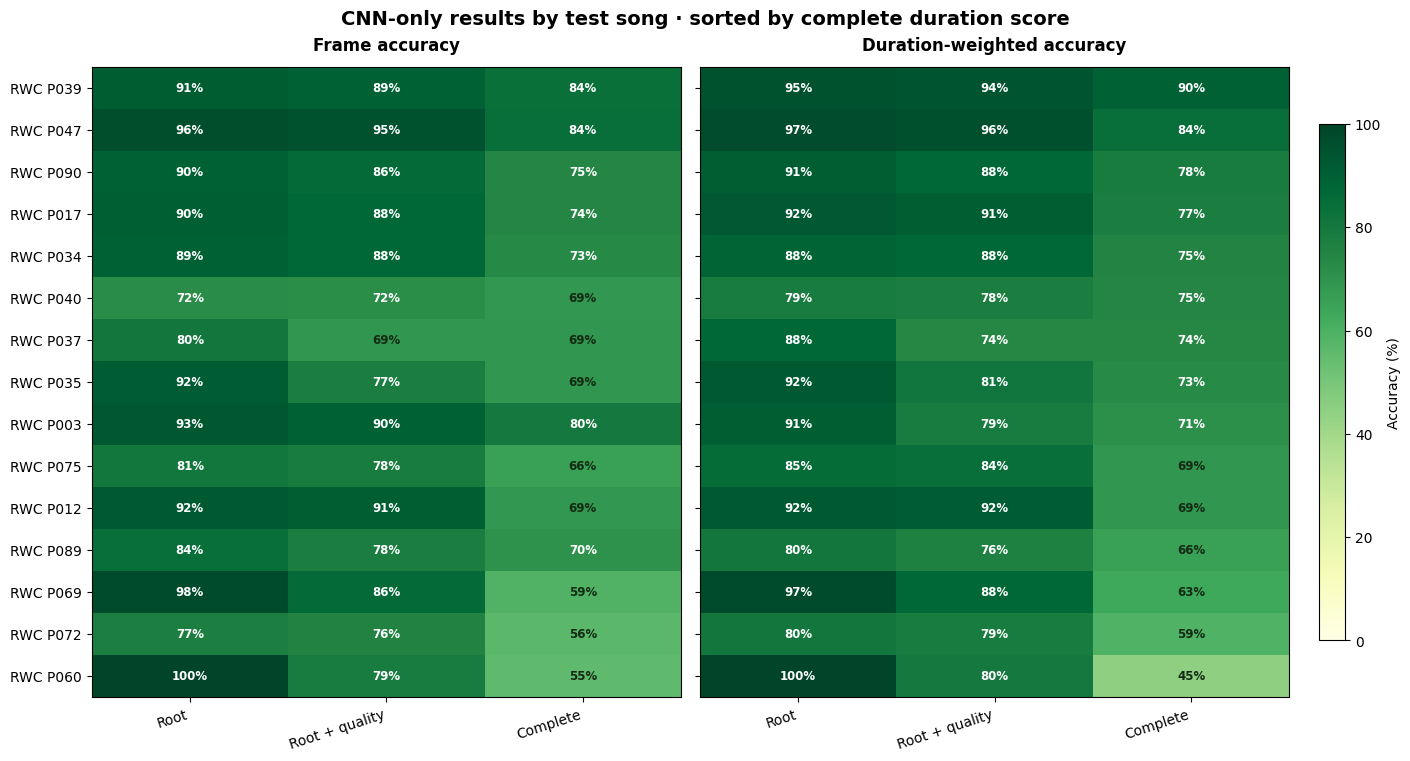

In [4]:
short_names = ['Frame · Root', 'Frame · Root + quality', 'Frame · Complete', 'Duration · Root', 'Duration · Root + quality', 'Duration · Complete']
per_song = pd.DataFrame(
    [[f"RWC P{item['song']:03d}"] + [item['cnn_only'][key] for key, _, _ in metric_info]
     for item in report['per_song']],
    columns=['Song'] + short_names,
).set_index('Song')
display(per_song.style.format('{:.2%}').background_gradient(cmap='YlGn', vmin=0, vmax=1))

order = per_song.iloc[:, -1].sort_values(ascending=False).index
ordered = per_song.loc[order]
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), sharey=True, constrained_layout=True)
for ax, columns, title in zip(axes, [range(3), range(3, 6)], ['Frame accuracy', 'Duration-weighted accuracy']):
    values = 100 * ordered.iloc[:, list(columns)].to_numpy()
    image = ax.imshow(values, cmap='YlGn', vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(3), ['Root', 'Root + quality', 'Complete'], rotation=18, ha='right')
    ax.set_yticks(range(len(ordered)), ordered.index)
    ax.set_title(title, fontweight='bold', pad=12)
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            value = values[row, column]
            ax.text(column, row, f'{value:.0f}%', ha='center', va='center', fontsize=8.5,
                    color='white' if value >= 70 else '#132a13', fontweight='bold')
fig.colorbar(image, ax=axes, label='Accuracy (%)', shrink=.82, pad=.025)
fig.suptitle('CNN-only results by test song · sorted by complete duration score', fontsize=14, fontweight='bold')
plt.show()

## Listen to a song

Put a song in `input/` and run the cells below. This transcribes it and plots a 24-second excerpt, plus the ground truth if the song is one of the annotated RWC test songs. It also writes an HTML player with the chords synced to the audio.

In [5]:
supported_audio = {'.wav', '.mp3', '.flac', '.ogg'}
audio_files = [path for path in sorted((ROOT / 'input').glob('*'))
               if path.suffix.lower() in supported_audio and path.stat().st_size > 0]
assert audio_files, 'Put an audio file in input/ first.'
display(pd.DataFrame({
    'Song': [path.stem for path in audio_files],
    'Format': [path.suffix.lower().lstrip('.').upper() for path in audio_files],
    'Size (MB)': [path.stat().st_size / 1_000_000 for path in audio_files],
}).style.hide(axis='index').format({'Size (MB)': '{:.1f}'}))

Song,Format,Size (MB)
RWC_P039,FLAC,32.5


In [6]:
audio_path = audio_files[0]
song = audio_path.stem
subprocess.run([sys.executable, 'transcribe.py', str(audio_path)], cwd=ROOT, env=env, check=True)

timeline = pd.read_csv(ROOT / 'output' / song / 'chords.csv')
annotation_path = ROOT / 'data/annotations' / f'{song}.csv'
ground_truth = None
if annotation_path.is_file():
    ground_truth = pd.read_csv(annotation_path, sep=';').rename(
        columns={'t_start': 'start_seconds', 't_end': 'end_seconds'},
    )

RWC_P039.flac: running CNN + HSMM ...
  108 chord segments -> output/RWC_P039/
  open output/RWC_P039/viewer.html to play it back with the chords


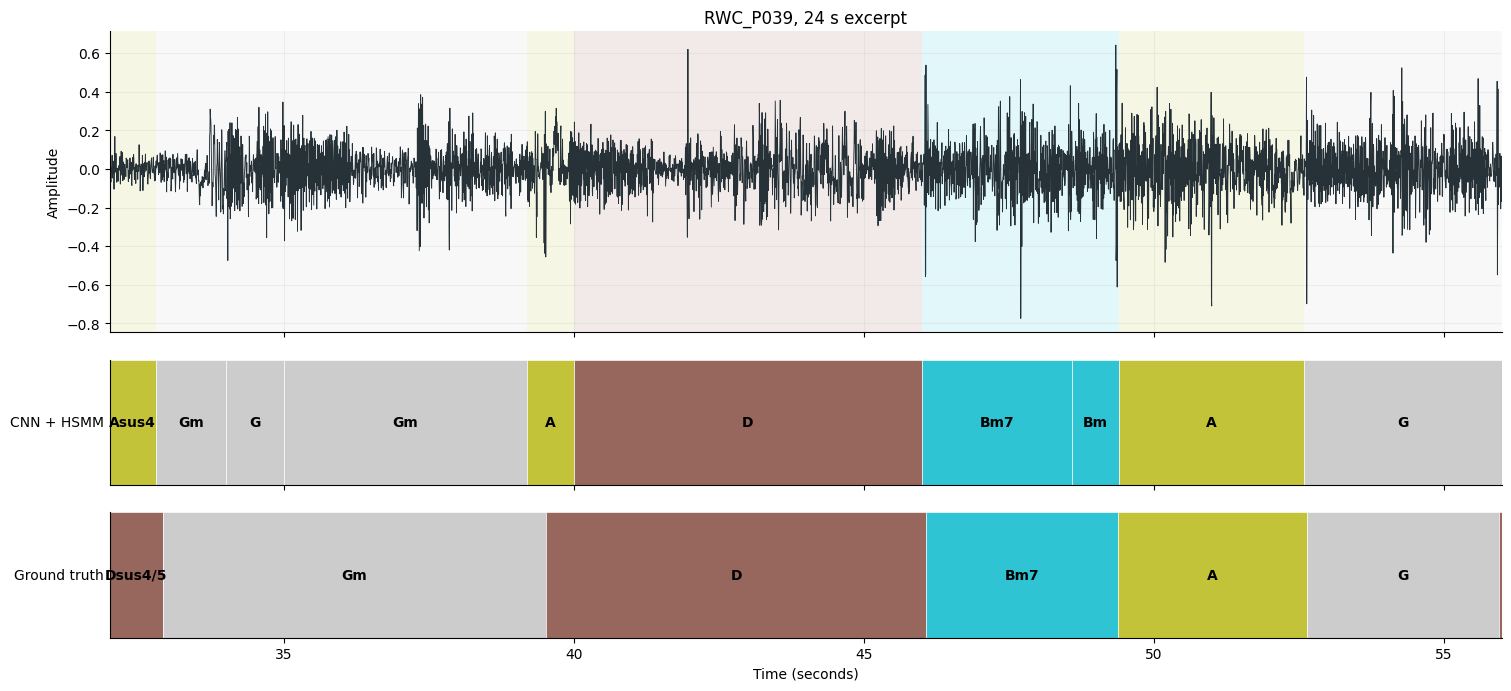

In [7]:
waveform, sample_rate = librosa.load(audio_path, sr=8_000, mono=True)
max_points = 60_000
stride = max(1, len(waveform) // max_points)
times = np.arange(0, len(waveform), stride) / sample_rate
duration = len(waveform) / sample_rate

roots = ['C#', 'Eb', 'F#', 'Ab', 'Bb', 'C', 'D', 'E', 'F', 'G', 'A', 'B', 'N']
palette = plt.get_cmap('tab20')(np.linspace(0, 1, len(roots)))
def chord_color(label):
    root = next((root for root in roots[:-1] if str(label).startswith(root)), 'N')
    return palette[roots.index(root)]

view_seconds = min(24, duration)
view_start = min(32, max(0, duration - view_seconds))
view_end = view_start + view_seconds
visible_wave = (times >= view_start) & (times <= view_end)

if ground_truth is not None:
    fig, (wave_ax, predicted_ax, truth_ax) = plt.subplots(3, 1, figsize=(15, 6.8), sharex=True,
        gridspec_kw={'height_ratios': [2.4, 1, 1], 'hspace': .10}, constrained_layout=True)
    plot_axes = (wave_ax, predicted_ax, truth_ax)
    title = f'{audio_path.stem}, 24 s excerpt'
else:
    fig, (wave_ax, predicted_ax) = plt.subplots(2, 1, figsize=(15, 5.2), sharex=True,
        gridspec_kw={'height_ratios': [2.4, 1], 'hspace': .10}, constrained_layout=True)
    truth_ax = None
    plot_axes = (wave_ax, predicted_ax)
    title = f'{audio_path.stem}, 24 s excerpt'
wave_ax.plot(times[visible_wave], waveform[::stride][visible_wave], color='#263238', linewidth=.65)
wave_ax.set(ylabel='Amplitude', title=title)
wave_ax.grid(alpha=.16)

label_threshold = .75
for event in timeline.itertuples(index=False):
    start, end, chord = event.start_seconds, event.end_seconds, str(event.chord)
    if end <= view_start or start >= view_end:
        continue
    color = chord_color(chord)
    wave_ax.axvspan(start, end, color=color, alpha=.12, linewidth=0)
    predicted_ax.axvspan(start, end, color=color, alpha=.9, ec='white', lw=.5)
    if min(end, view_end) - max(start, view_start) >= label_threshold:
        predicted_ax.text((max(start, view_start) + min(end, view_end)) / 2, .5, chord, ha='center', va='center',
                      fontsize=10, fontweight='bold')

if ground_truth is not None:
    for event in ground_truth.itertuples(index=False):
        start, end, chord = event.start_seconds, event.end_seconds, str(event.chord)
        if end <= view_start or start >= view_end:
            continue
        display_chord = chord.replace(':maj7', 'maj7').replace(':min7', 'm7').replace(':maj', '').replace(':min', 'm').replace(':', '')
        truth_ax.axvspan(start, end, color=chord_color(display_chord), alpha=.9, ec='white', lw=.5)
        if min(end, view_end) - max(start, view_start) >= label_threshold:
            truth_ax.text((max(start, view_start) + min(end, view_end)) / 2, .5, display_chord,
                          ha='center', va='center', fontsize=10, fontweight='bold')

predicted_ax.set(xlim=(view_start, view_end), ylim=(0, 1), yticks=[])
predicted_ax.set_ylabel('CNN + HSMM', rotation=0, ha='right', va='center')
if truth_ax is not None:
    truth_ax.set(xlim=(view_start, view_end), ylim=(0, 1), yticks=[], xlabel='Time (seconds)')
    truth_ax.set_ylabel('Ground truth', rotation=0, ha='right', va='center')
else:
    predicted_ax.set_xlabel('Time (seconds)')
for axis in plot_axes:
    axis.spines[['top', 'right']].set_visible(False)
plt.show()

### Player

The generated viewer plays the audio with the current, previous and upcoming chords. Click any chord card to seek.

In [8]:
viewer_path = ROOT / 'output' / song / 'viewer.html'
print(f'Open {viewer_path.relative_to(ROOT)} in a browser.')

Open output/RWC_P039/viewer.html in a browser.
